In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import set_config
set_config(display="text")


from sklearn import datasets

# 교차 검증 수행 해주는 함수 
from sklearn.model_selection import cross_val_score

# DecisionTreeClassifier 와 RandomForestClassifier 정확도 비교해보자
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


# 선생님과 동일한 결과를 위해 랜덤시드 설정 
np.random.seed(5)



# 손글씨 데이터 로드

In [2]:
mnist = datasets.load_digits()

# 입력 데이터와 정답을 저장 
features, labels = mnist.data, mnist.target
print(features.shape)

(1797, 64)


# 교차 검증
교차 검증을 10번 수행하여, 10번의 교차 검증 평균 정확도를 저장함.

In [3]:
def cross_validation(classifier, features, labels):
    cv_scores = []

    for i in range(10):
        scores = cross_val_score(classifier, features, labels, cv=10, scoring='accuracy')        
        cv_scores.append(scores.mean())

    return cv_scores

In [4]:
dct = DecisionTreeClassifier()
dt_cv_scores = cross_validation(dct, features, labels)

rf = RandomForestClassifier()
rf_cv_scores = cross_validation(rf, features, labels)

In [5]:
print(dt_cv_scores)
print(rf_cv_scores)

[np.float64(0.8280229671011794), np.float64(0.8235630043451273), np.float64(0.8224674115456239), np.float64(0.8235692116697703), np.float64(0.8341464928615766), np.float64(0.8185692116697704), np.float64(0.8241247672253259), np.float64(0.8180136561142148), np.float64(0.8235630043451272), np.float64(0.8258038485412786)]
[np.float64(0.9526939788950962), np.float64(0.9487957790192427), np.float64(0.9510211049037863), np.float64(0.9549286157666046), np.float64(0.9471322160148976), np.float64(0.9487988826815641), np.float64(0.952122905027933), np.float64(0.9454531346989447), np.float64(0.9460180012414648), np.float64(0.9471322160148976)]


# 랜덤포레스트 vs 의사결정트리 시각화  

라인 차트를 통해 랜덤포레스트가 의사결정트리보다 정확도가 높은 것을 확인

In [6]:
cv_list = [
            ['random_forest', rf_cv_scores],
            ['decision_tree', dt_cv_scores]
          ]

df = pd.DataFrame.from_dict(dict(cv_list))

<Axes: >

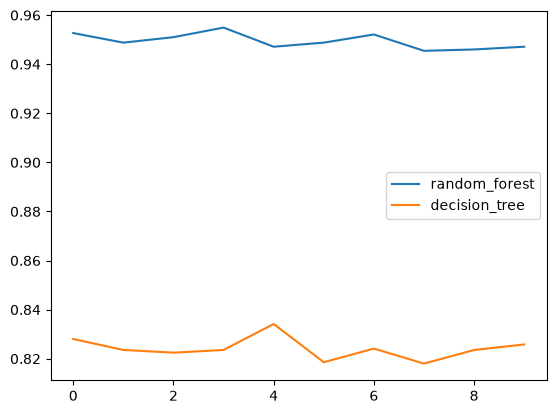

In [7]:
df.plot()

# 의사결정트리 정확도

In [8]:
print(np.mean(dt_cv_scores))

0.8241843575418993


# 랜덤포레스트 정확도

In [9]:
print(np.mean(rf_cv_scores))

0.9494096834264433
